<a href="https://colab.research.google.com/github/ZPA2k/SocialMediaAnalysisCourseHW/blob/main/EDA_using_Json_files.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 6 — Exploratory data analysis and real-world data

This week combines **JSON/nested data** with **exploratory data analysis (EDA)**.

Use the JSON file provided on Moodle.

## Part A — From nested JSON to analytical data

1. Read the JSON file.
2. Inspect its structure before flattening it. What kinds of nested objects or lists does it contain?
3. Convert the data into one or more useful pandas DataFrames. You may use `pd.json_normalize()` and other pandas operations.
4. Keep track of the normalization/flattening steps you perform.
5. How many normalization steps did you use?
6. Did you flatten *everything*? Explain why complete flattening is or is not useful for this dataset.

## Part B — Exploratory data analysis

Using the DataFrame you created:

7. Use `.head()`/`.tail()` to inspect observations.
8. Use `.shape`, `.info()`, `.describe()`, `.isna()`, `.value_counts()`, or other appropriate tools to understand the dataset.
9. Identify at least two variables that could be analytically interesting.
10. Create **two appropriate visualizations** that reveal something about the data.
11. Write 3–5 sentences explaining what you learned from the EDA. Distinguish what the data actually show from possible interpretations.

## Optional extension

Choose another dataset that interests you and conduct a shorter EDA. You may use Kaggle or another appropriate source, but do not simply copy an existing analysis notebook. Adapt the analysis to the dataset and questions that interest you.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import json
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
#Part A

In [ ]:
#1
with open("/content/drive/MyDrive/Colab Notebooks/raw_nyc_phil.json") as f:
  data = json.load(f)

In [ ]:
#2
data.keys()

dict_keys(['programs'])

In [ ]:
type(data['programs'])

list

In [ ]:
len(data['programs'])

13954

In [ ]:
data['programs'][0]

{'season': '1842-43',
 'orchestra': 'New York Philharmonic',
 'concerts': [{'Date': '1842-12-07T05:00:00Z',
   'eventType': 'Subscription Season',
   'Venue': 'Apollo Rooms',
   'Location': 'Manhattan, NY',
   'Time': '8:00PM'}],
 'programID': '3853',
 'works': [{'workTitle': 'SYMPHONY NO. 5 IN C MINOR, OP.67',
   'conductorName': 'Hill, Ureli Corelli',
   'ID': '52446*',
   'soloists': [],
   'composerName': 'Beethoven,  Ludwig  van'},
  {'workTitle': 'OBERON',
   'composerName': 'Weber,  Carl  Maria Von',
   'conductorName': 'Timm, Henry C.',
   'ID': '8834*4',
   'soloists': [{'soloistName': 'Otto, Antoinette',
     'soloistRoles': 'S',
     'soloistInstrument': 'Soprano'}],
   'movement': '"Ozean, du Ungeheuer" (Ocean, thou mighty monster), Reiza (Scene and Aria), Act II'},
  {'workTitle': 'QUINTET, PIANO, D MINOR, OP. 74',
   'ID': '3642*',
   'soloists': [{'soloistName': 'Scharfenberg, William',
     'soloistRoles': 'A',
     'soloistInstrument': 'Piano'},
    {'soloistName': 'Hi

In [ ]:
#3
pd.json_normalize(data['programs'])

,season,orchestra,concerts,programID,works,id
0,1842-43,New York Philharmonic,"[{'Date': '1842-12-07T05:00:00Z', 'eventType':...",3853,"[{'workTitle': 'SYMPHONY NO. 5 IN C MINOR, OP....",38e072a7-8fc9-4f9a-8eac-3957905c0002
1,1842-43,New York Philharmonic,"[{'Date': '1843-02-18T05:00:00Z', 'eventType':...",5178,[{'workTitle': 'SYMPHONY NO. 3 IN E FLAT MAJOR...,c7b2b95c-5e0b-431c-a340-5b37fc860b34
2,1842-43,Musicians from the New York Philharmonic,"[{'Date': '1843-04-07T05:00:00Z', 'eventType':...",10785,"[{'workTitle': 'EGMONT, OP.84', 'composerName'...",894e1a52-1ae5-4fa7-aec0-b99997555a37
3,1842-43,New York Philharmonic,"[{'Date': '1843-04-22T05:00:00Z', 'eventType':...",5887,"[{'workTitle': 'SYMPHONY NO. 2 IN D MAJOR, OP....",34ec2c2b-3297-4716-9831-b538310462b7
4,1843-44,New York Philharmonic,"[{'Date': '1843-11-18T05:00:00Z', 'eventType':...",305,"[{'workTitle': 'SYMPHONY NO. 7 IN A MAJOR, OP....",610a4acc-94e4-4cd6-bdc1-8ad020edc7e9
...,...,...,...,...,...,...
13949,2016-17,Musicians from the New York Philharmonic,"[{'Date': '2017-06-24T04:00:00Z', 'eventType':...",14189,"[{'workTitle': 'QUARTET, STRING, NO. 3 (MISHIM...",3d50968c-2e8b-405f-969c-ba36f941f393
13950,2016-17,New York Philharmonic,"[{'Date': '2017-07-02T04:00:00Z', 'eventType':...",14146,"[{'workTitle': 'SYMPHONY NO. 9, E MINOR, OP.95...",adb9fc8b-95bc-47d0-9f4b-78fc242f1f8f
13951,2016-17,New York Philharmonic,"[{'Date': '2017-07-03T04:00:00Z', 'eventType':...",14148,[{'workTitle': 'SYMPHONY NO. 7 IN E MINOR (SO...,f072c652-c452-4ad4-975a-f6abd5ff8b4d
13952,2016-17,New York Philharmonic,"[{'Date': '2017-07-04T04:00:00Z', 'eventType':...",14136,"[{'workTitle': 'SYMPHONY NO. 9, E MINOR, OP.95...",68625626-8085-44e4-bdb3-d8e6ac51c95b


In [ ]:
#4
works_df = pd.json_normalize(
    data["programs"], record_path="works",
    meta=["programID", "season", "orchestra"])
works_df

,workTitle,conductorName,ID,soloists,composerName,movement,interval,movement.em,movement._,workTitle.em,workTitle._,programID,season,orchestra
0,"SYMPHONY NO. 5 IN C MINOR, OP.67","Hill, Ureli Corelli",52446*,[],"Beethoven, Ludwig van",NaN,NaN,NaN,NaN,NaN,NaN,3853,1842-43,New York Philharmonic
1,OBERON,"Timm, Henry C.",8834*4,"[{'soloistName': 'Otto, Antoinette', 'soloistR...","Weber, Carl Maria Von","""Ozean, du Ungeheuer"" (Ocean, thou mighty mons...",NaN,NaN,NaN,NaN,NaN,3853,1842-43,New York Philharmonic
2,"QUINTET, PIANO, D MINOR, OP. 74",NaN,3642*,"[{'soloistName': 'Scharfenberg, William', 'sol...","Hummel, Johann",NaN,NaN,NaN,NaN,NaN,NaN,3853,1842-43,New York Philharmonic
3,NaN,NaN,0*,[],NaN,NaN,Intermission,NaN,NaN,NaN,NaN,3853,1842-43,New York Philharmonic
4,OBERON,"Etienne, Denis G.",8834*3,[],"Weber, Carl Maria Von",Overture,NaN,NaN,NaN,NaN,NaN,3853,1842-43,New York Philharmonic
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
82788,MEMORIES OF MARNYI STONE,"Gersen, Joshua",12636*,[],"Feng, Shuya",NaN,NaN,NaN,NaN,NaN,NaN,14136,2016-17,New York Philharmonic
82789,"SYMPHONY NO. 9, E MINOR, OP.95 (FROM THE NEW W...","Gersen, Joshua",2877*4,[],"Dvorak, Antonín",Allegro con fuoco,NaN,NaN,NaN,NaN,NaN,14136,2016-17,New York Philharmonic
82790,QUIET CITY,"Gilbert, Alan",52332*,"[{'soloistName': 'Martin, Christopher', 'soloi...","Copland, Aaron",NaN,NaN,NaN,NaN,NaN,NaN,14147,2016-17,New York Philharmonic
82791,"JUNGLE, THE (SYMPHONY NO. 4)","Gilbert, Alan",12071*,[{'soloistName': 'Jazz at Lincoln Center Orche...,"Marsalis, Wynton",NaN,NaN,NaN,NaN,NaN,NaN,14147,2016-17,New York Philharmonic


In [ ]:
concerts_df = pd.json_normalize(
    data["programs"], record_path="concerts",
    meta=["programID", "season"])
concerts_df

,Date,eventType,Venue,Location,Time,programID,season
0,1842-12-07T05:00:00Z,Subscription Season,Apollo Rooms,"Manhattan, NY",8:00PM,3853,1842-43
1,1843-02-18T05:00:00Z,Subscription Season,Apollo Rooms,"Manhattan, NY",8:00PM,5178,1842-43
2,1843-04-07T05:00:00Z,Special,Apollo Rooms,"Manhattan, NY",8:00PM,10785,1842-43
3,1843-04-22T05:00:00Z,Subscription Season,Apollo Rooms,"Manhattan, NY",8:00PM,5887,1842-43
4,1843-11-18T05:00:00Z,Subscription Season,Apollo Rooms,"Manhattan, NY",None,305,1843-44
...,...,...,...,...,...,...,...
21602,2017-06-24T04:00:00Z,Chamber,Guild Hall,"East Hampton, NY",None,14189,2016-17
21603,2017-07-02T04:00:00Z,Tour,Shanghai Symphony Hall,"Shanghai, CHINA",7:30PM,14146,2016-17
21604,2017-07-03T04:00:00Z,Tour,Shanghai Symphony Hall,"Shanghai, CHINA",7:30PM,14148,2016-17
21605,2017-07-04T04:00:00Z,Tour - Young People's Concert,Shanghai Symphony Hall--Chamber Hall,"Shanghai, CHINA",7:30PM,14136,2016-17


In [ ]:
s = works_df[["programID", "ID", "soloists"]].explode("soloists").dropna(subset=["soloists"])
soloists_df = pd.concat(
    [s.drop(columns="soloists").reset_index(drop=True),
     pd.json_normalize(s["soloists"].tolist())], axis=1)
soloists_df

,programID,ID,soloistName,soloistRoles,soloistInstrument
0,3853,8834*4,"Otto, Antoinette",S,Soprano
1,3853,3642*,"Scharfenberg, William",A,Piano
2,3853,3642*,"Hill, Ureli Corelli",A,Violin
3,3853,3642*,"Derwort, G. H.",A,Viola
4,3853,3642*,"Boucher, Alfred",A,Cello
...,...,...,...,...,...
56189,14136,2877*6,"Xu, Weiqin",S,Baritone
56190,14147,52332*,"Martin, Christopher",S,Trumpet
56191,14147,52332*,"Shryock, Grace",S,English Horn
56192,14147,12071*,Jazz at Lincoln Center Orchestra with Wynton M...,S,Jazz Ensemble


In [ ]:
#5 I used 3 normalization steps, for "works","concerts" and "soloists"

In [ ]:
#6 No, if everything is flattened, the data will be inflated.
#For instance, some works contain multiple soloists, which will create multiple rows with the same works.
#Doing this is not efficient, therefore, I did not flatten everything.

In [ ]:
#Part B

In [ ]:
#7
works_df.head(10)

,workTitle,conductorName,ID,soloists,composerName,movement,interval,movement.em,movement._,workTitle.em,workTitle._,programID,season,orchestra
0,"SYMPHONY NO. 5 IN C MINOR, OP.67","Hill, Ureli Corelli",52446*,[],"Beethoven, Ludwig van",NaN,NaN,NaN,NaN,NaN,NaN,3853,1842-43,New York Philharmonic
1,OBERON,"Timm, Henry C.",8834*4,"[{'soloistName': 'Otto, Antoinette', 'soloistR...","Weber, Carl Maria Von","""Ozean, du Ungeheuer"" (Ocean, thou mighty mons...",NaN,NaN,NaN,NaN,NaN,3853,1842-43,New York Philharmonic
2,"QUINTET, PIANO, D MINOR, OP. 74",NaN,3642*,"[{'soloistName': 'Scharfenberg, William', 'sol...","Hummel, Johann",NaN,NaN,NaN,NaN,NaN,NaN,3853,1842-43,New York Philharmonic
3,NaN,NaN,0*,[],NaN,NaN,Intermission,NaN,NaN,NaN,NaN,3853,1842-43,New York Philharmonic
4,OBERON,"Etienne, Denis G.",8834*3,[],"Weber, Carl Maria Von",Overture,NaN,NaN,NaN,NaN,NaN,3853,1842-43,New York Philharmonic
5,ARMIDA,"Timm, Henry C.",8835*1,"[{'soloistName': 'Otto, Antoinette', 'soloistR...","Rossini, Gioachino",Duet,NaN,NaN,NaN,NaN,NaN,3853,1842-43,New York Philharmonic
6,"FIDELIO, OP. 72","Timm, Henry C.",8837*6,"[{'soloistName': 'Horn, Charles Edward', 'solo...","Beethoven, Ludwig van","""In Des Lebens Fruhlingstagen...O spur ich nic...",NaN,NaN,NaN,NaN,NaN,3853,1842-43,New York Philharmonic
7,"ABDUCTION FROM THE SERAGLIO,THE, K.384","Timm, Henry C.",8336*4,"[{'soloistName': 'Otto, Antoinette', 'soloistR...","Mozart, Wolfgang Amadeus","""Ach Ich liebte,"" Konstanze (aria)",NaN,NaN,NaN,NaN,NaN,3853,1842-43,New York Philharmonic
8,"OVERTURE NO. 1, D MINOR, OP. 38","Timm, Henry C.",5543*,[],"Kalliwoda, Johann W.",NaN,NaN,NaN,NaN,NaN,NaN,3853,1842-43,New York Philharmonic
9,"SYMPHONY NO. 3 IN E FLAT MAJOR, OP. 55 (EROICA)","Hill, Ureli Corelli",52437*,[],"Beethoven, Ludwig van",NaN,NaN,NaN,NaN,NaN,NaN,5178,1842-43,New York Philharmonic


In [ ]:
works_df.tail()

,workTitle,conductorName,ID,soloists,composerName,movement,interval,movement.em,movement._,workTitle.em,workTitle._,programID,season,orchestra
82788,MEMORIES OF MARNYI STONE,"Gersen, Joshua",12636*,[],"Feng, Shuya",NaN,NaN,NaN,NaN,NaN,NaN,14136,2016-17,New York Philharmonic
82789,"SYMPHONY NO. 9, E MINOR, OP.95 (FROM THE NEW W...","Gersen, Joshua",2877*4,[],"Dvorak, Antonín",Allegro con fuoco,NaN,NaN,NaN,NaN,NaN,14136,2016-17,New York Philharmonic
82790,QUIET CITY,"Gilbert, Alan",52332*,"[{'soloistName': 'Martin, Christopher', 'soloi...","Copland, Aaron",NaN,NaN,NaN,NaN,NaN,NaN,14147,2016-17,New York Philharmonic
82791,"JUNGLE, THE (SYMPHONY NO. 4)","Gilbert, Alan",12071*,[{'soloistName': 'Jazz at Lincoln Center Orche...,"Marsalis, Wynton",NaN,NaN,NaN,NaN,NaN,NaN,14147,2016-17,New York Philharmonic
82792,C JAM BLUES,NaN,8152*,[{'soloistName': 'Jazz at Lincoln Center Orche...,"Ellington, Duke",NaN,NaN,NaN,NaN,NaN,NaN,14147,2016-17,New York Philharmonic


In [ ]:
#8
works_df.shape

(82793, 14)

In [ ]:
works_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 82793 entries, 0 to 82792
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   workTitle      71422 non-null  object
 1   conductorName  66314 non-null  object
 2   ID             82793 non-null  object
 3   soloists       82793 non-null  object
 4   composerName   71427 non-null  object
 5   movement       24989 non-null  object
 6   interval       11366 non-null  object
 7   movement.em    227 non-null    object
 8   movement._     114 non-null    object
 9   workTitle.em   5 non-null      object
 10  workTitle._    5 non-null      object
 11  programID      82793 non-null  object
 12  season         82793 non-null  object
 13  orchestra      82793 non-null  object
dtypes: object(14)
memory usage: 8.8+ MB


In [ ]:
works_df.describe(include="all")

,workTitle,conductorName,ID,soloists,composerName,movement,interval,movement.em,movement._,workTitle.em,workTitle._,programID,season,orchestra
count,71422,66314,82793,82793,71427,24989,11366,227,114,5,5,82793,82793,82793
unique,11269,794,16648,8295,2766,4648,4,84,37,4,4,13885,175,12
top,"MEISTERSINGER, DIE, WWV 96","Damrosch, Walter",0*,[],"Wagner, Richard",Overture,Intermission,The Swan of Tuonela,(name of Marmein dance),FIFTHS,"QUARTET, STRING, OP. 76, NO. 2, D MINOR, H.III...",9542,1945-46,New York Philharmonic
freq,784,5427,11278,56725,4929,3419,11278,80,18,2,2,50,1364,56167


In [ ]:
works_df.isna().sum()

,0
workTitle,11371
conductorName,16479
ID,0
soloists,0
composerName,11366
movement,57804
interval,71427
movement.em,82566
movement._,82679
workTitle.em,82788


In [ ]:
works_df["composerName"].value_counts().head(10)

,count
composerName,
"Wagner, Richard",4929
"Beethoven, Ludwig van",4536
"Tchaikovsky, Pyotr Ilyich",3703
"Mozart, Wolfgang Amadeus",2649
"Brahms, Johannes",2534
"Strauss, Richard",1625
"Mendelssohn, Felix",1500
"Berlioz, Hector",1400
"Bach, Johann Sebastian",1388


In [ ]:
concerts_df["Location"].value_counts()

,count
Location,
"Manhattan, NY",18381
"Brooklyn, NY",287
"Philadelphia, PA",159
"Queens, NY",100
"Washington, DC",98
...,...
"Castleton, VA",1
"South Bend, IN",1
"Trieste, ITALY",1


In [ ]:
concerts_df["eventType"].value_counts()

,count
eventType,
Subscription Season,12871
Tour,2067
Stadium Concert,1828
Young People's Concert,874
Parks,502
Student Concert,391
Special,382
Chamber,365
Runout,293


In [ ]:
#9 The variables that would be anylatically interesting might be the "composerName" and the "decade".
# Since these variables can show which composer was most performed and also in which period the ochestra peaked its popularity.

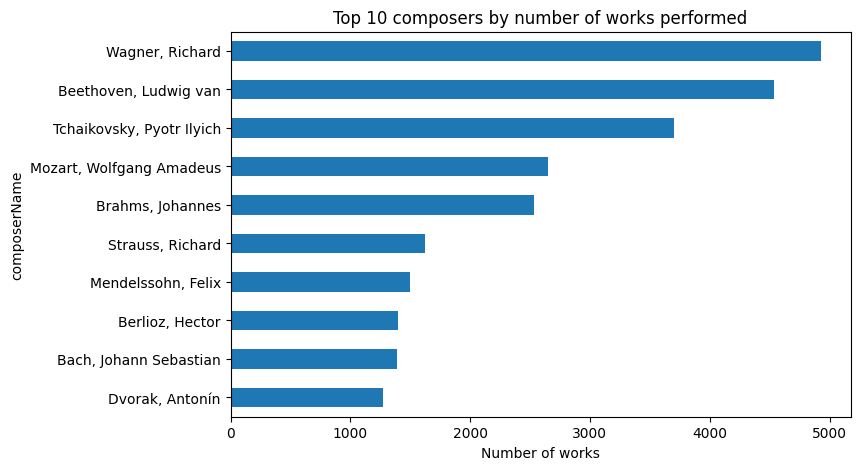

In [ ]:
#10
# Plot 1
comp = works_df["composerName"].str.replace(r"\s+", " ", regex=True)
comp.value_counts().head(10).sort_values().plot.barh(figsize=(8, 5))
plt.title("Top 10 composers by number of works performed")
plt.xlabel("Number of works")
plt.show()

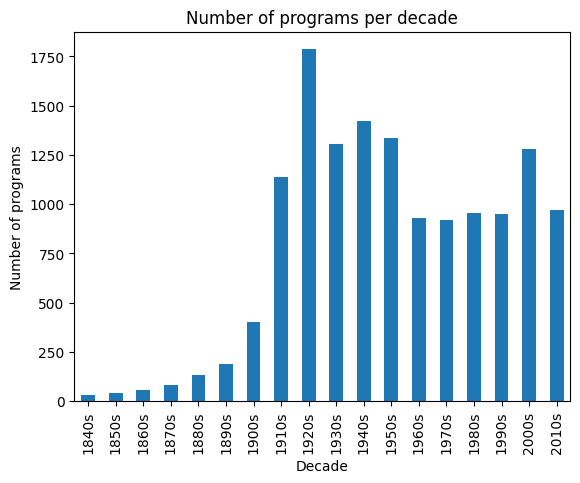

In [ ]:
# Plot 2
concerts_df["decade"] = concerts_df["season"].str[:3] + "0s"
concerts_df.groupby("decade")["programID"].nunique().plot.bar()
plt.title("Number of programs per decade")
plt.ylabel("Number of programs")
plt.xlabel("Decade")
plt.show()

In [ ]:
# 11 (1) The works of Wagner, Beethoven and Tchaikovsky are the most performed. This might be the popularity or these composers owned many works.
# (2) The number of programs peaked around 1920s to 1950s, which might indicate the popularity of ochestra.
# However, we cannot conclude for sure, since the records from the earlier years might be incomplete or not recorded, hence very low numbers.
# (3) Most of the concerts are performed in Manhattan, New York (almost 80%), because of the Broadway.


In [ ]:
# We can do the popularity trend about certain thing(Bach's work performed over the years)/
# Maybe the number of programs during the economic depression, stock markets crashes (can pair with the economics)

In [ ]:
# Limitations are also important, think about why and how the results came out to be.